# 🔍 Task-Specific EDA: Text Classification Diagnostics
### In-Case Diagnostics for Class Balance, Imbalance Ratios & Target Profile
Tujuan: Memetakan sebaran kelas target (*class distribution*), menghitung rasio ketimpangan (*imbalance ratio*), menganalisis perbedaan panjang teks antar kelas, dan menentukan strategi fungsi loss serta validasi silang (Cross-Validation).


In [1]:
# 1. Master Config
TRAIN_PATH = "../demo_data/train.csv"
TEST_PATH = "../demo_data/test.csv"
LABEL_COL = "label"
TEXT_COL = "full_text"


In [2]:
# 2. Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


In [3]:
# 3. Load Data & Basic Shape
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Train samples: {len(train_df)}, Test samples: {len(test_df)}")
print(f"Unique classes ({train_df[LABEL_COL].nunique()}): {train_df[LABEL_COL].unique().tolist()}")


Train samples: 60, Test samples: 15
Unique classes (3): ['positive', 'neutral', 'negative']


In [4]:
# 4. Class Distribution & Imbalance Audit
class_counts = train_df[LABEL_COL].value_counts()
class_pcts = train_df[LABEL_COL].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({
    'Count': class_counts,
    'Percentage (%)': class_pcts.round(2)
})

imbalance_ratio = class_counts.max() / max(1, class_counts.min())

print("=== CLASS IMBALANCE AUDIT ===")
print(summary_df)
print(f"\nImbalance Ratio (Max / Min): {imbalance_ratio:.2f} : 1")


=== CLASS IMBALANCE AUDIT ===
          Count  Percentage (%)
label                          
positive     20           33.33
neutral      20           33.33
negative     20           33.33

Imbalance Ratio (Max / Min): 1.00 : 1


C:\Users\yasse\AppData\Local\Temp\ipykernel_45300\529799426.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, ax=axes[0], palette=palette)


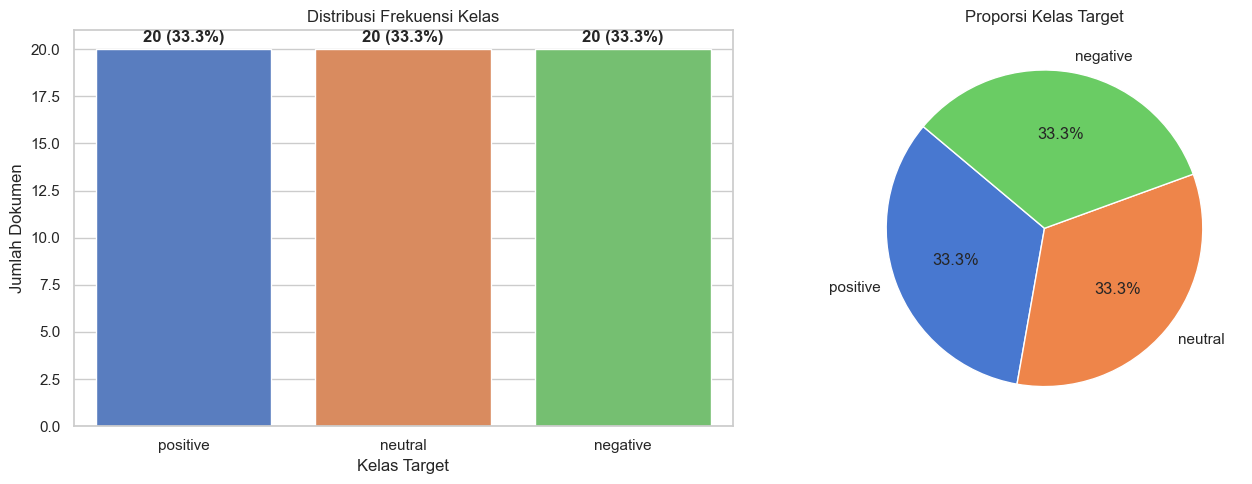

In [5]:
# 5. Visualizing Class Balance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
palette = sns.color_palette("muted", len(class_counts))
sns.barplot(x=class_counts.index, y=class_counts.values, ax=axes[0], palette=palette)
axes[0].set_title("Distribusi Frekuensi Kelas")
axes[0].set_ylabel("Jumlah Dokumen")
axes[0].set_xlabel("Kelas Target")
for idx, val in enumerate(class_counts.values):
    axes[0].text(idx, val + max(class_counts.values)*0.02, f"{val} ({class_pcts.iloc[idx]:.1f}%)", ha='center', fontweight='bold')

# Pie chart
axes[1].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%', colors=palette, startangle=140)
axes[1].set_title("Proporsi Kelas Target")

plt.tight_layout()
plt.show()


C:\Users\yasse\AppData\Local\Temp\ipykernel_45300\4278347144.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=LABEL_COL, y='word_count', data=train_df, palette=palette)


=== AVERAGE WORD COUNT PER CLASS ===
          count   mean   std  min  max
label                                 
negative     20  12.85  1.63   10   16
neutral      20  12.10  1.48   10   15
positive     20  12.90  1.12   11   15


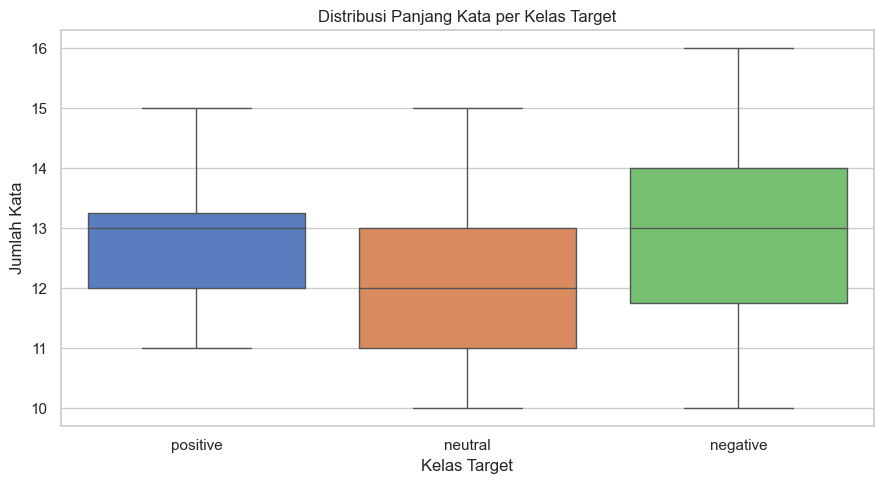

In [6]:
# 6. Text Length Profiling per Class
train_df['word_count'] = train_df[TEXT_COL].astype(str).str.split().str.len()

print("=== AVERAGE WORD COUNT PER CLASS ===")
print(train_df.groupby(LABEL_COL)['word_count'].agg(['count', 'mean', 'std', 'min', 'max']).round(2))

plt.figure(figsize=(9, 5))
sns.boxplot(x=LABEL_COL, y='word_count', data=train_df, palette=palette)
plt.title("Distribusi Panjang Kata per Kelas Target")
plt.ylabel("Jumlah Kata")
plt.xlabel("Kelas Target")
plt.tight_layout()
plt.show()


### 📋 Master Decision Matrix (Classification):
1. **Rasio Imbalance $\le 2:1$ (Balanced):** Gunakan fungsi loss standar `nn.CrossEntropyLoss()` atau default `LGBMClassifier`. Metrik **Accuracy** dan **Macro F1** sejalan.
2. **Rasio Imbalance $2:1$ s/d $5:1$ (Moderate Imbalance):**
   * Berikan bobot kelas terbalik: `weights = total_samples / (num_classes * class_samples)`.
   * Berikan bobot ini pada `CrossEntropyLoss(weight=weights)`.
   * Prioritaskan metrik **Macro F1** (jangan gunakan Akurasi murni!).
3. **Rasio Imbalance $> 5:1$ (Extreme Imbalance / Fraud / Toksisitas Langka):**
   * Gunakan modul `modular_variations/model_configs/focal_loss_imbalance/` ($\gamma=2.0$).
   * Terapkan ambang batas probabilitas adaptif via `modular_variations/post_processing/probability_threshold_tuning/`.
   * **WAJIB gunakan `StratifiedKFold`** untuk memastikan setiap fold memiliki proporsi kelas minoritas yang sama!
